# phase-separated RBM, Metropolis sampling, SR + SGD

In [9]:
import jax
import jax.numpy as jnp
import netket as nk
from netket.sampler.gibbs import GibbsSampler
import matplotlib.pyplot as plt
from netket.operator.spin import sigmax, sigmaz, sigmay
import tqdm as notebook_tqdm

N = 10
J, h = 1.0, 1.0
g = 0.5
hi = nk.hilbert.Spin(s=1/2, N=N)

n_chains = 64
sweep_size = N
n_samples = 1024

n_iter = 300

H = sum(
    -J * (sigmaz(hi, i) @ sigmaz(hi, (i + 1) % N))
    -h * sigmax(hi, i)
    -g * (sigmaz(hi, i) @ sigmay(hi, (i + 1) % N))
    for i in range(N)
)

# ModPhase model, sampler (metropolis) , vstate
ModPhase = nk.models.RBMModPhase(alpha=1, param_dtype=jnp.float64)
Metropolis = nk.sampler.MetropolisLocal(hi, n_chains=n_chains, sweep_size=sweep_size)
vstate_ModPhase = nk.vqs.MCState(Metropolis, ModPhase, n_samples=n_samples)

# PhaseSep model, sampler (Gibbs), vstate
amplitude = nk.models.RBM(alpha=1, use_visible_bias=False)
phase = nk.models.RBM(alpha=1, use_visible_bias=False)

PhaseSep = nk.models.PhaseSeparated(amplitude=amplitude, phase=phase)
Gibbs = GibbsSampler(hi, n_chains=n_chains, sweep_size=1)
vstate_PhaseSep = nk.vqs.MCState(Gibbs, PhaseSep, n_samples=n_samples)

# start both runs from the same model parameters
p = vstate_ModPhase.parameters

vstate_PhaseSep.parameters = {
    "amplitude": {"Dense": p["Dense_0"]},
    "phase": {"Dense": p["Dense_1"]},
}

# shared optimizer
optimizer = nk.optimizer.Sgd(learning_rate=0.05)

# Initialize driver for each
vmc_ModPhase = nk.driver.VMC(H, optimizer, variational_state=vstate_ModPhase)
log_ModPhase = nk.logging.RuntimeLog()

vmc_PhaseSep = nk.driver.VMC(H, optimizer, variational_state=vstate_PhaseSep)
log_PhaseSep = nk.logging.RuntimeLog()

vmc_ModPhase.run(n_iter=n_iter, out=log_ModPhase)
energy_history_ModPhase = log_ModPhase.data["Energy"]["Mean"].real

vmc_PhaseSep.run(n_iter=n_iter, out=log_PhaseSep)
energy_history_PhaseSep = log_PhaseSep.data["Energy"]["Mean"].real

exact_energy = nk.exact.lanczos_ed(H, compute_eigenvectors=False)[0]

  0%|          | 0/300 [00:00<?, ?it/s]

  0%|          | 0/300 [00:00<?, ?it/s]

Exact ground energy: -13.303417279846675
Last sampled energy (ModPhase): -13.278430804564096
Last sampled energy (PhaseSep): -13.305509305528021


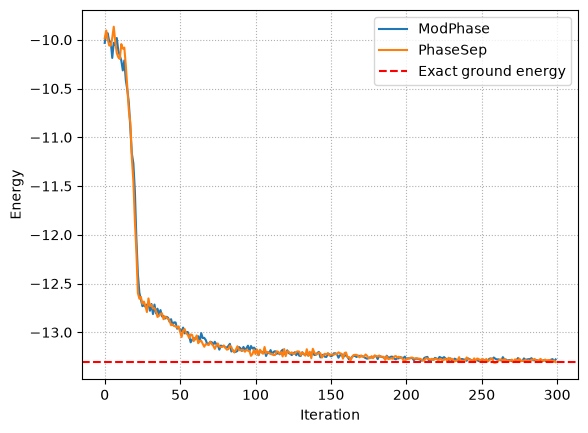

In [10]:
print(f"Exact ground energy: {exact_energy}")
print(f"Last sampled energy (ModPhase): {energy_history_ModPhase[-1]}")
print(f"Last sampled energy (PhaseSep): {energy_history_PhaseSep[-1]}")

plt.plot(energy_history_ModPhase, label="ModPhase")
plt.plot(energy_history_PhaseSep, label="PhaseSep")
plt.axhline(exact_energy, color="red", linestyle="--", label="Exact ground energy")
plt.xlabel("Iteration")
plt.ylabel("Energy")

#ticks_start = 150
#plt.xlim(left=ticks_start)
#top = max(energy_history_ModPhase[ticks_start:])
#bottom = min(energy_history_PhaseSep[ticks_start:])

#plt.ylim(top=top, bottom=bottom)

plt.legend(loc="upper right")
plt.grid(linestyle = "dotted")
plt.show()